# 01 — USGS NWIS: Gallatin Basin

**Goal:** Confirm we can pull from the four NWIS endpoints we need for v1, end-to-end, for the Gallatin basin. By the end of this notebook we should have:

1. A list of every active streamflow gauge in the Gallatin (HUC8 10020008 + 10020009), discovered via the **Site Service** (no hardcoded site numbers).
2. A full **daily-values** history for the canonical Gallatin Gateway gauge (06043500).
3. **Day-of-year percentile statistics** (P10/P50/P90) for the same gauge from the Statistics Service.
4. A **current instantaneous reading** (latest CFS, height, temp) — the kind of thing that lives in `current.json`.
5. A **plot** showing the most recent year of daily flow against the P10–P90 envelope. This is the "is the river normal?" chart that anchors the per-gauge UI.

**Reminder of storage strategy:** we keep daily values as history, never instantaneous. Current snapshot is fetched fresh on every cron tick and overwrites `current.json`. Stats are static reference data.

In [1]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from datetime import datetime, timedelta

NWIS_BASE = "https://waterservices.usgs.gov/nwis"
GALLATIN_HUCS = ["10020008", "10020009"]  # Upper + Lower Gallatin
GATEWAY_SITE = "06043500"  # Gallatin River near Gallatin Gateway — canonical reference gauge

# Polite User-Agent — USGS asks for one for tracking and rate-limit decisions
HEADERS = {"User-Agent": "RiverLine/0.1 (Ito Geospatial; itogeospatial.com)"}

/Users/ianvandusen/Desktop/Ito/itogeo/repos/line/riverline/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


## 1. Site discovery — every Gallatin streamflow gauge

We use the **Site Service** with `parameterCd=00060` (discharge in CFS) and `siteStatus=active` so we only get live gauges. Output format `rdb` is USGS's tab-delimited dialect — easier to parse than the WaterML/WaterAlert XML.

In [2]:
def fetch_sites_by_huc(hucs, parameter_cd="00060", site_status="active"):
    params = {
        "format": "rdb",
        "huc": ",".join(hucs),
        "parameterCd": parameter_cd,
        "siteStatus": site_status,
        "siteType": "ST",  # stream
        "hasDataTypeCd": "iv",  # has instantaneous data available
        "siteOutput": "expanded",  # need expanded output to get drain_area_va, alt_va, etc.
    }
    r = requests.get(f"{NWIS_BASE}/site/", params=params, headers=HEADERS, timeout=30)
    r.raise_for_status()
    # RDB format: '#'-prefixed comment lines, then a header line, then a type line, then data rows
    lines = [ln for ln in r.text.splitlines() if not ln.startswith("#")]
    header = lines[0].split("\t")
    data_rows = [ln.split("\t") for ln in lines[2:] if ln.strip()]
    df = pd.DataFrame(data_rows, columns=header)
    for c in ("dec_lat_va", "dec_long_va", "alt_va", "drain_area_va"):
        if c in df.columns:
            df[c] = pd.to_numeric(df[c], errors="coerce")
    return df

sites = fetch_sites_by_huc(GALLATIN_HUCS)
print(f"Found {len(sites)} active streamflow gauges in Gallatin HUCs {GALLATIN_HUCS}")
display_cols = [c for c in ["site_no", "station_nm", "dec_lat_va", "dec_long_va", "huc_cd", "drain_area_va", "alt_va"] if c in sites.columns]
sites[display_cols]

Found 5 active streamflow gauges in Gallatin HUCs ['10020008', '10020009']


,site_no,station_nm,dec_lat_va,dec_long_va,huc_cd,drain_area_va,alt_va
0,06043120,"Gallatin River above Deer Creek, near Big Sky, MT",45.297278,-111.211392,10020008,537.6,5875.00
1,06043500,"Gallatin River near Gallatin Gateway, MT",45.497300,-111.270708,10020008,819.0,5167.67
2,06048650,E Gallatin R ab Water Reclamation Fa nr Bozema...,45.725667,-111.066194,10020008,226.0,4625.00
3,06050000,Hyalite C at Hyalite R S nr Bozeman MT,45.563328,-111.071889,10020008,48.5,5539.60
4,06052500,Gallatin River at Logan MT,45.886247,-111.442008,10020008,1789.0,4086.42


## 2. Daily values for the canonical Gateway gauge

Pull the full period of record of daily mean discharge for site 06043500. This is what we'd persist to `data/history/06043500.parquet` in production — incrementally appended after the initial backfill.

In [3]:
def fetch_daily_values(site_no, parameter_cd="00060", start="1900-01-01", end=None):
    if end is None:
        end = datetime.utcnow().strftime("%Y-%m-%d")
    params = {
        "format": "json",
        "sites": site_no,
        "startDT": start,
        "endDT": end,
        "parameterCd": parameter_cd,
        "statCd": "00003",  # mean
    }
    r = requests.get(f"{NWIS_BASE}/dv/", params=params, headers=HEADERS, timeout=60)
    r.raise_for_status()
    js = r.json()
    series = js["value"]["timeSeries"]
    if not series:
        return pd.DataFrame(columns=["date", "discharge_cfs"])
    values = series[0]["values"][0]["value"]
    df = pd.DataFrame(values)
    df["date"] = pd.to_datetime(df["dateTime"]).dt.tz_localize(None).dt.normalize()
    df["discharge_cfs"] = pd.to_numeric(df["value"], errors="coerce")
    return df[["date", "discharge_cfs"]].dropna().reset_index(drop=True)

dv = fetch_daily_values(GATEWAY_SITE)
print(f"Daily values for {GATEWAY_SITE}: {len(dv):,} rows")
print(f"Period of record: {dv['date'].min().date()}  →  {dv['date'].max().date()}")
print(f"Min / mean / max CFS: {dv['discharge_cfs'].min():.0f} / {dv['discharge_cfs'].mean():.0f} / {dv['discharge_cfs'].max():.0f}")
dv.tail()

Daily values for 06043500: 33,181 rows
Period of record: 1930-06-01  →  2026-04-06
Min / mean / max CFS: 153 / 799 / 8970


,date,discharge_cfs
33176,2026-04-02,626
33177,2026-04-03,576
33178,2026-04-04,524
33179,2026-04-05,527
33180,2026-04-06,537


## 3. Day-of-year percentiles from the Statistics Service

The NWIS Statistics Service computes per-day-of-year statistics over the full period of record. We ask for `statTypeCd=P10,P25,P50,P75,P90` so the frontend can render flow vs. "normal" bands. This is *the* feature that distinguishes us from wkcc — telling the user not just what the flow is, but whether it's typical for this date.

In [4]:
def fetch_doy_percentiles(site_no, parameter_cd="00060"):
    params = {
        "format": "rdb",
        "sites": site_no,
        "statReportType": "daily",
        "statTypeCd": "p10,p25,p50,p75,p90,mean",
        "parameterCd": parameter_cd,
    }
    r = requests.get(f"{NWIS_BASE}/stat/", params=params, headers=HEADERS, timeout=30)
    r.raise_for_status()
    lines = [ln for ln in r.text.splitlines() if not ln.startswith("#")]
    header = lines[0].split("\t")
    rows = [ln.split("\t") for ln in lines[2:] if ln.strip()]
    df = pd.DataFrame(rows, columns=header)
    for c in ["month_nu", "day_nu", "p10_va", "p25_va", "p50_va", "p75_va", "p90_va", "mean_va"]:
        if c in df.columns:
            df[c] = pd.to_numeric(df[c], errors="coerce")
    return df

stats = fetch_doy_percentiles(GATEWAY_SITE)
print(f"Stats rows: {len(stats)} (expected ~366 — one per day-of-year)")
stats[["month_nu", "day_nu", "p10_va", "p25_va", "p50_va", "p75_va", "p90_va"]].head()

Stats rows: 366 (expected ~366 — one per day-of-year)


,month_nu,day_nu,p10_va,p25_va,p50_va,p75_va,p90_va
0,1,1,231,260,302,332,NaN
1,1,2,235,256,298,335,NaN
2,1,3,230,261,294,321,NaN
3,1,4,226,260,296,333,NaN
4,1,5,232,260,304,343,NaN


## 4. Current instantaneous snapshot

Fetch the latest IV reading for discharge (00060), gage height (00065), and water temperature (00010). This is the shape of what goes into `current.json` per gauge — fetched fresh every cron tick, never persisted to history.

In [5]:
def fetch_current_snapshot(site_no, parameter_cds=("00060", "00065", "00010")):
    params = {
        "format": "json",
        "sites": site_no,
        "parameterCd": ",".join(parameter_cds),
        "siteStatus": "active",
    }
    r = requests.get(f"{NWIS_BASE}/iv/", params=params, headers=HEADERS, timeout=30)
    r.raise_for_status()
    js = r.json()
    snapshot = {"site_no": site_no}
    for ts in js["value"]["timeSeries"]:
        var = ts["variable"]
        code = var["variableCode"][0]["value"]
        unit = var["unit"]["unitCode"]
        latest = ts["values"][0]["value"][-1] if ts["values"][0]["value"] else None
        if latest is not None:
            snapshot[f"{var['variableName'].split(',')[0]} ({unit})"] = {
                "value": float(latest["value"]) if latest["value"] not in ("", "-999999") else None,
                "timestamp": latest["dateTime"],
                "parameter_cd": code,
            }
    return snapshot

snapshot = fetch_current_snapshot(GATEWAY_SITE)
for k, v in snapshot.items():
    print(f"  {k}: {v}")

  site_no: 06043500
  Streamflow (ft3/s): {'value': 557.0, 'timestamp': '2026-04-07T08:00:00.000-06:00', 'parameter_cd': '00060'}
  Gage height (ft): {'value': 1.73, 'timestamp': '2026-04-07T08:00:00.000-06:00', 'parameter_cd': '00065'}


## 5. The "is the river normal?" plot

Combine the recent year of daily values with the percentile envelope. This is the chart that anchors the per-gauge detail page in the frontend.

**Reading the chart:**
- Shaded band = P10–P90 of historical flows for each calendar day (typical year-to-year range)
- Darker band = P25–P75 (interquartile / "normal")
- Dashed line = P50 (median)
- Solid line = the actual flow over the last year

Saved plot to 01_gateway_percentiles.png


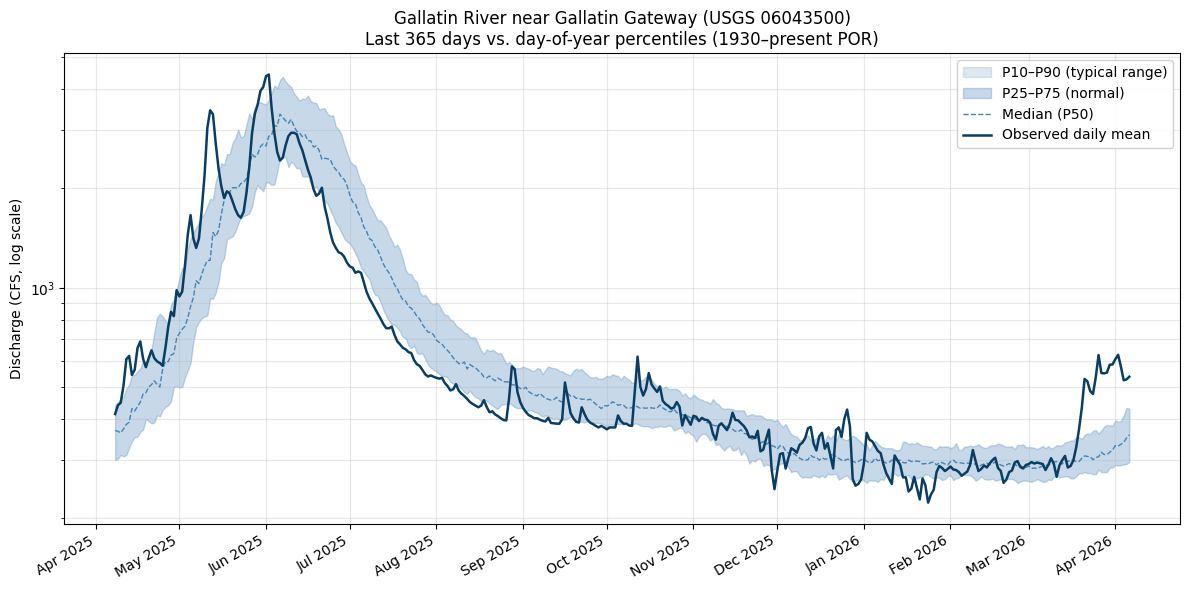

In [6]:
# Last 365 days of observed flow
today = pd.Timestamp.utcnow().tz_localize(None).normalize()
recent = dv[dv["date"] > today - pd.Timedelta(days=365)].copy()
recent["month_day"] = list(zip(recent["date"].dt.month, recent["date"].dt.day))

# Build a calendar-day -> percentiles lookup so we can align stats to the recent dates
stats_lookup = stats.set_index(["month_nu", "day_nu"])[["p10_va", "p25_va", "p50_va", "p75_va", "p90_va"]]

def lookup(md, col):
    try:
        return stats_lookup.loc[md, col]
    except KeyError:
        return float("nan")

for col in ["p10_va", "p25_va", "p50_va", "p75_va", "p90_va"]:
    recent[col] = [lookup(md, col) for md in recent["month_day"]]

fig, ax = plt.subplots(figsize=(12, 6))
ax.fill_between(recent["date"], recent["p10_va"], recent["p90_va"], alpha=0.18, color="steelblue", label="P10–P90 (typical range)")
ax.fill_between(recent["date"], recent["p25_va"], recent["p75_va"], alpha=0.30, color="steelblue", label="P25–P75 (normal)")
ax.plot(recent["date"], recent["p50_va"], color="steelblue", linestyle="--", linewidth=1, label="Median (P50)")
ax.plot(recent["date"], recent["discharge_cfs"], color="#0a3d62", linewidth=1.8, label="Observed daily mean")

ax.set_yscale("log")
ax.set_ylabel("Discharge (CFS, log scale)")
ax.set_title(f"Gallatin River near Gallatin Gateway (USGS {GATEWAY_SITE})\nLast 365 days vs. day-of-year percentiles ({dv['date'].min().year}–present POR)")
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.grid(True, which="both", alpha=0.3)
ax.legend(loc="upper right", framealpha=0.9)
fig.autofmt_xdate()
plt.tight_layout()

# Save to disk so we can sanity-check the rendering even if the notebook viewer is unavailable
fig.savefig("01_gateway_percentiles.png", dpi=110)
print("Saved plot to 01_gateway_percentiles.png")
plt.show()

## Findings (executed 2026-04-07)

**End-to-end success — all four NWIS endpoints work, all four data shapes understood.**

### Site discovery (HUC 10020008 + 10020009)
Five active streamflow gauges with IV data in the Gallatin basin:

| site_no | station |
|---|---|
| 06043120 | Gallatin River above Deer Creek, near Big Sky |
| **06043500** | **Gallatin River near Gallatin Gateway** *(canonical)* |
| 06048650 | E Gallatin R above Water Reclamation, near Bozeman |
| 06050000 | Hyalite Creek at Hyalite Reservoir, nr Bozeman |
| 06052500 | Gallatin River at Logan |

**Plan correction:** the original PLAN.md listed "Gallatin at Manhattan" — it's actually **Gallatin at Logan (06052500)**. Also no W Fork / Taylor Fork gauges exist with active IV — those tributaries don't have telemetry. Will fix in PLAN.md.

### Daily values at Gateway (06043500)
- **33,181 rows**, period of record **1930-06-01 → present** (~96 years)
- Min / mean / max: **153 / 799 / 8,970 CFS**
- Latest reading: 537 CFS on 2026-04-06 — pre-runoff baseflow as expected for early April
- JSON parsing was straightforward; one timeSeries per (site, parameter) pair, values nested under `value[0].value`

### Statistics service (366 day-of-year rows)
- Confirmed 366 rows (one per calendar day, leap-year inclusive)
- **Quirk:** P90 returns empty for early-January days (Jan 1–5) at this gauge despite 95+ years of data. Other percentiles fine. **Investigate in Phase 2** — likely a USGS computation threshold or column-name issue. Not blocking; the plot still renders by treating those as NaN.

### Current snapshot (IV)
- Discharge **557 CFS** and gage height **1.73 ft** at 2026-04-07 08:00 MDT
- **No water temperature** — parameter 00010 isn't reported at Gateway. The gauge has no temp sensor. Need to handle gracefully in `current.json` (omit field rather than null) and plan for the fact that not every gauge will have all three parameters.
- IV JSON shape is identical to DV — same parsing code can handle both.

### Plot
- Rendered as `01_gateway_percentiles.png` (147 KB). Reads correctly: classic snowmelt hydrograph with the peak in late May/June 2025 above 5,000 CFS, recession through summer/fall, winter baseflow near 300 CFS, current April 2026 reading creeping back up as melt begins.
- Log Y-axis is essential — linear axis would hide the winter baseflow detail under the runoff peak.

### Implications for Phase 2 (ingestion service)
1. **Site discovery code** (`fetch_sites_by_huc`) is essentially the production version — promote it to `src/ingest/usgs.py` as `nwis_sites()`.
2. **DV / stats / IV fetchers** all work and need only minor cleanup (error handling, retries, response caching) before they're production-ready. The notebook's parsing logic is sound.
3. **Per-gauge variability matters** — not every gauge has all three parameters (no temp at Gateway). The pipeline must enumerate what each gauge actually publishes via the site service before assuming structure.
4. **POR backfill is one HTTP call** — 96 years of DV came back in one request, no pagination needed. Future cron runs only need to pull the latest day(s).
5. **`siteOutput=expanded` is required** if we want drainage area / elevation / county metadata. The basic output is too thin for the gauge detail page.
6. **Add to investigation queue:** the P90 NaN for early-January days, and whether parameter 00011 (temperature C) is sometimes used in place of 00010 (F) at MT gauges.